# Modelos ARIMA Estacionales (SARIMA)

Los modelos **Seasonal ARIMA (SARIMA)** extienden los modelos ARIMA tradicionales para capturar patrones de **estacionalidad** en las series de tiempo.

Un modelo SARIMA se denota como:

$$
SARIMA(p,d,q)(P,D,Q)_S
$$

donde:

- **\(p\)**: orden autorregresivo no estacional.
- **\(d\)**: número de diferenciaciones no estacionales.
- **\(q\)**: orden de media móvil no estacional.
- **\(P\)**: orden autorregresivo estacional.
- **\(D\)**: número de diferenciaciones estacionales.
- **\(Q\)**: orden de media móvil estacional.
- **\(S\)**: período estacional.

Por ejemplo,

$$
SARIMA(0,1,1)(0,1,1)_{12}
$$

representa una serie mensual con una estacionalidad anual (\(S=12\)), una diferenciación regular, una diferenciación estacional y componentes MA tanto estacionales como no estacionales.

Los modelos SARIMA son especialmente útiles para modelar series con patrones repetitivos, como:

- Ventas mensuales.
- Consumo de energía.
- Demanda de agua.
- Empleo y producción industrial.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (10, 5)
plt.style.use('fivethirtyeight')

In [ ]:
# Cargar el dataset de candy
candy = pd.read_csv('./dataset/candy.csv')
candy.head()

In [ ]:
c

## Series de Tiempo Estacionales

### Datos estacionales
- Presentan **patrones predecibles y repetitivos**.
- Los patrones se repiten después de un período fijo de tiempo (\(S\)).

Ejemplos:
- Ventas mensuales (\(S=12\))
- Consumo eléctrico diario (\(S=24\))
- Ventas trimestrales (\(S=4\))

## Descomposición Estacional

Una serie de tiempo puede descomponerse en tres componentes:

$$
\text{Serie} = \text{Tendencia} + \text{Estacionalidad} + \text{Residual}
$$

En este ejercicio se descompone la serie de **producción mensual de leche por vaca en EE.UU.** para identificar:

- **Tendencia:** comportamiento de largo plazo.
- **Estacionalidad:** patrón que se repite periódicamente.
- **Residual:** variación aleatoria no explicada.

Dado que la serie es **mensual**, se supone inicialmente un período estacional de:

$$
S = 12
$$

aunque el período estacional debe verificarse a partir de los datos.

In [69]:
milk_production = pd.read_csv('./dataset/milk_production.csv', index_col='date', parse_dates=True)
milk_production = milk_production.asfreq('MS')
milk_production.head()

,pounds_per_cow
date,
1962-01-01,589.0
1962-02-01,561.0
1962-03-01,640.0
1962-04-01,656.0
1962-05-01,727.0


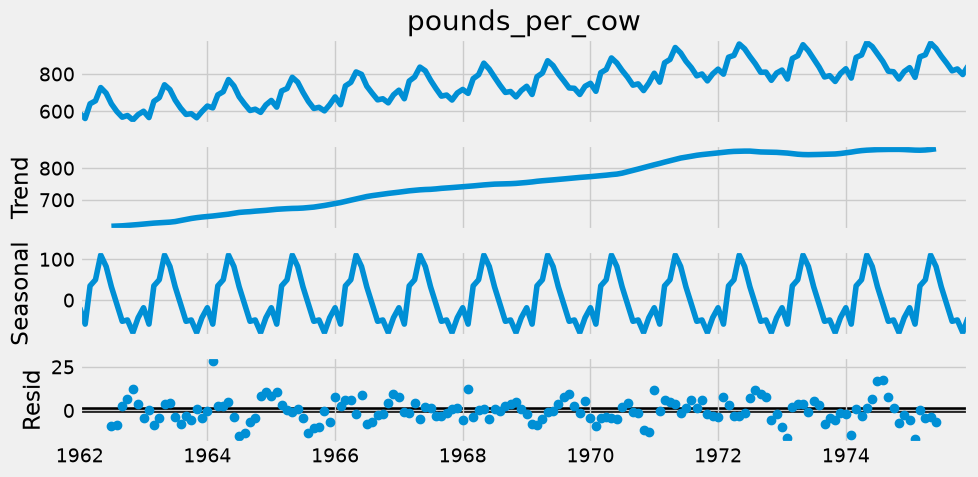

In [70]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform additive decomposition
decomp = seasonal_decompose(milk_production['pounds_per_cow'], period=12)

# Plot decomposition
decomp.plot();
plt.tight_layout();

## ACF y PACF Estacionales

La serie del número de consumidores de agua en Londres no muestra un patrón estacional evidente a simple vista.

Sin embargo, la **ACF** y la **PACF** son herramientas más adecuadas para detectar estacionalidad oculta.

En este ejercicio se utilizan para:

- Identificar la presencia de patrones estacionales.
- Determinar el período estacional \(S\).
- Ayudar en la especificación de un modelo **SARIMA**.

> Una serie puede presentar estacionalidad incluso cuando esta no es evidente visualmente en el gráfico original.

In [71]:
water = pd.read_csv('./dataset/water.csv', index_col='date', parse_dates=True)
water = water.asfreq('MS')
water.head()

,water_consumers
date,
1983-01-01,24963
1983-02-01,27380
1983-03-01,32588
1983-04-01,25511
1983-05-01,32313


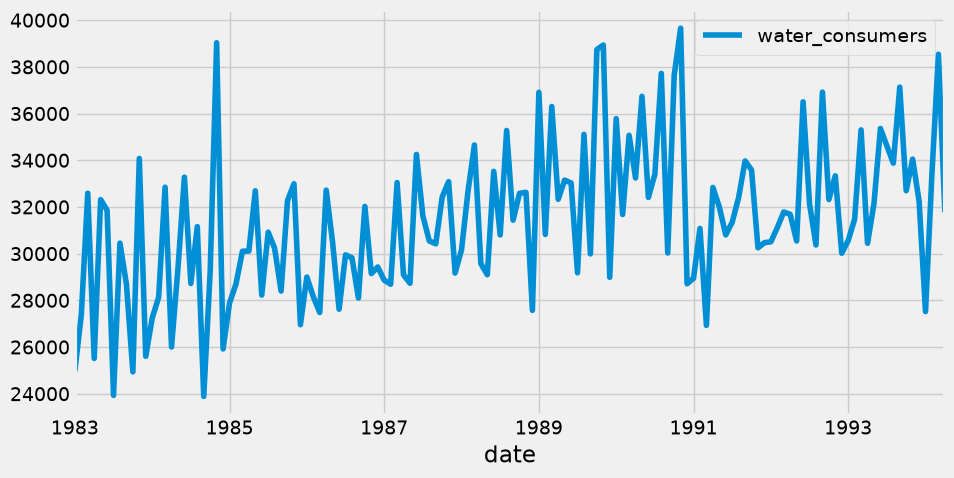

In [72]:
water.plot();

## ACF y PACF Estacionales

En este ejercicio se utilizan la **ACF** y la **PACF** para detectar la presencia de estacionalidad en la serie de consumidores de agua en Londres.

Como la serie **no es estacionaria**, primero se elimina la tendencia restando una **media móvil**:

```python
water_detrended = water - water.rolling(window=15).mean()

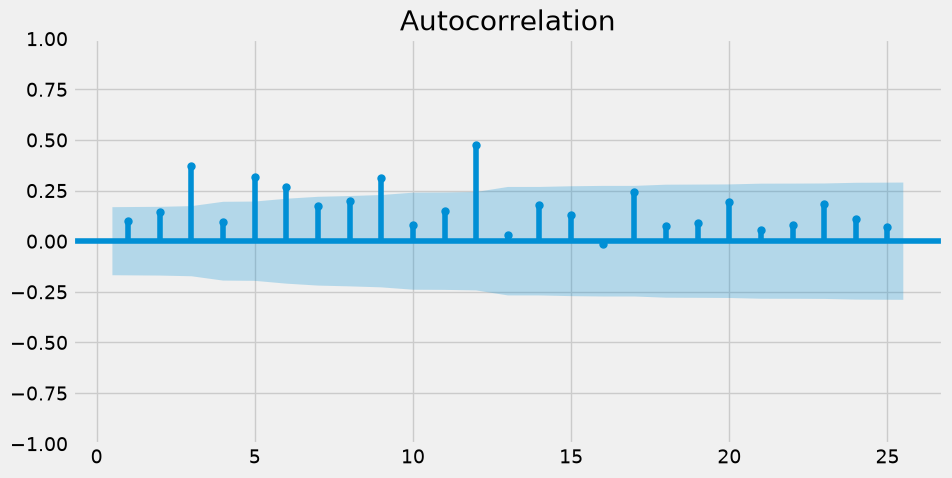

In [73]:
from statsmodels.graphics.tsaplots import plot_acf

# Create figure and subplot
fig, ax1 = plt.subplots()

# Plot the ACF on ax1
plot_acf(water['water_consumers'], lags=25, zero=False, ax=ax1);

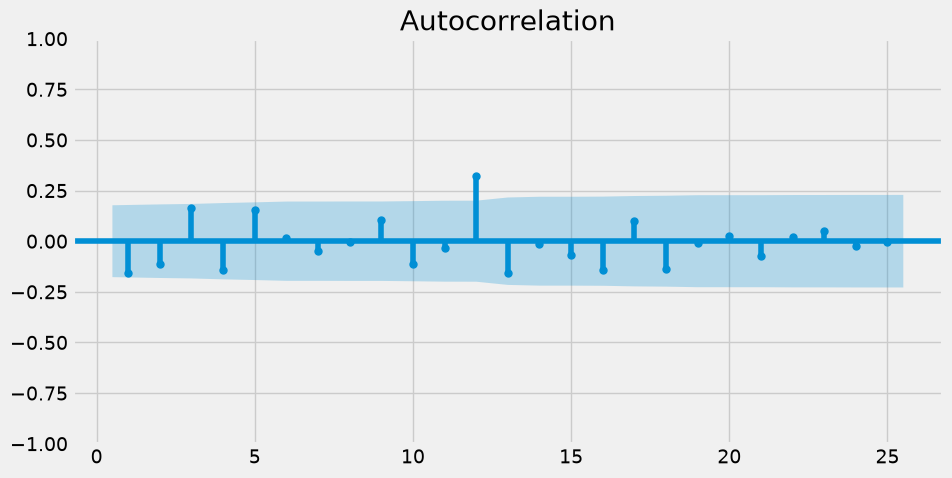

In [74]:
# Subtract the rolling mean
water_2 = water - water.rolling(15).mean()

# Drop the NaN values
water_2 = water_2.dropna()

# Create figure and subplots
fig, ax1 = plt.subplots()

# Plot the ACF
plot_acf(water_2['water_consumers'], lags=25, zero=False, ax=ax1);

### Conclusión

A partir de la figura se observa un pico significativo en el **rezago 12**, lo que indica que el componente estacional se repite cada:

$$
S = 12
$$

✅ La serie presenta una **estacionalidad anual** (12 períodos), por lo que al modelarla debe considerarse un componente estacional con:

$$
\boxed{S=12}
$$

por ejemplo, mediante un modelo **SARIMA**.

# Modelos SARIMA

Los modelos **Seasonal ARIMA (SARIMA)** extienden los modelos ARIMA tradicionales para capturar patrones de **estacionalidad** en las series de tiempo.

## Notación

$$
\text{SARIMA}(p,d,q)(P,D,Q)_S
$$

### Órdenes no estacionales

- **\(p\)**: orden autorregresivo (AR).
- **\(d\)**: número de diferenciaciones.
- **\(q\)**: orden de media móvil (MA).

### Órdenes estacionales

- **\(P\)**: orden autorregresivo estacional.
- **\(D\)**: número de diferenciaciones estacionales.
- **\(Q\)**: orden de media móvil estacional.
- **\(S\)**: número de períodos por ciclo estacional.

---

## Ejemplo: Modelo ARIMA

Un modelo:

$$
\text{ARIMA}(2,0,1)
$$

se expresa como:

$$
y_t =
a_1y_{t-1}
+a_2y_{t-2}
+m_1\varepsilon_{t-1}
+\varepsilon_t
$$

donde el valor actual depende de los dos períodos anteriores y del error del período previo.

---

## Ejemplo: Modelo SARIMA

Un modelo:

$$
\text{SARIMA}(0,0,0)(2,0,1)_7
$$

se expresa como:

$$
y_t =
a_7y_{t-7}
+a_{14}y_{t-14}
+m_7\varepsilon_{t-7}
+\varepsilon_t
$$

En este caso, la dependencia ocurre cada:

$$
S=7
$$

por ejemplo, en una serie diaria con estacionalidad semanal.

---

## Diferenciación estacional

La diferenciación estacional elimina patrones que se repiten cada \(S\) períodos:

$$
\Delta y_t = y_t - y_{t-S}
$$

Es decir, se resta el valor actual con el valor observado una temporada atrás.

Por ejemplo:

- Datos mensuales: \(S=12\)
- Datos trimestrales: \(S=4\)
- Datos diarios con estacionalidad semanal: \(S=7\)


## Ajuste de Modelos SARIMA

El ajuste de modelos **SARIMA** es el paso final del proceso de modelado de series de tiempo con estacionalidad.

El objetivo es familiarizarse con los diferentes órdenes del modelo:

$$
\text{SARIMA}(p,d,q)(P,D,Q)_S
$$

donde:

- **\(p,d,q\)**: componentes no estacionales.
- **\(P,D,Q\)**: componentes estacionales.
- **\(S\)**: período estacional.

En este ejercicio se ajustan diferentes modelos SARIMA a una o varias series de tiempo para:

- Identificar la estructura temporal adecuada.
- Comparar modelos mediante criterios como **AIC** y **BIC**.
- Seleccionar el modelo que mejor describe la serie y proporciona mejores pronósticos.

In [75]:
df1 = pd.read_csv('./dataset/df1.csv', index_col=0, parse_dates=True)
df2 = pd.read_csv('./dataset/df2.csv', index_col=0, parse_dates=True)
df3 = pd.read_csv('./dataset/df3.csv', index_col=0, parse_dates=True)

In [76]:
df1 = df1.asfreq('d')
df2 = df2.asfreq('d')
df3 = df3.asfreq('d')

C:\Users\RYZEN 7\AppData\Local\Temp\ipykernel_38660\3204507180.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  df1 = df1.asfreq('d')
C:\Users\RYZEN 7\AppData\Local\Temp\ipykernel_38660\3204507180.py:2: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  df2 = df2.asfreq('d')
C:\Users\RYZEN 7\AppData\Local\Temp\ipykernel_38660\3204507180.py:3: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  df3 = df3.asfreq('d')


In [77]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Create a SARIMAX model
model = SARIMAX(df1, order=(1, 0, 0), seasonal_order=(1, 1, 0, 7))

# Fit the model
results = model.fit()

# Print the results summary
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                     
=========================================================================================
Dep. Variable:                                 Y   No. Observations:                   90
Model:             SARIMAX(1, 0, 0)x(1, 1, 0, 7)   Log Likelihood                -556.243
Date:                           Wed, 15 Jul 2026   AIC                           1118.486
Time:                                   19:02:35   BIC                           1125.742
Sample:                               01-01-2013   HQIC                          1121.401
                                    - 03-31-2013                                         
Covariance Type:                             opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1032      0.103      1.002      0.316      -0.099       0.305
ar.S.L7        0.2781      0.104      2.665      0.008       0.074       0.483
sigma2      3.858e+04   7224.680      5.340      0.000    2.44e+04    5.27e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 1.69
Prob(Q):                              0.97   Prob(JB):                         0.43
Heteroskedasticity (H):               1.35   Skew:                            -0.15
Prob(H) (two-sided):                  0.43   Kurtosis:                         2.37
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [78]:
# Create a SARIMAX model
model = SARIMAX(df2, order=(2, 1, 1), seasonal_order=(1, 0, 0, 4))

# Fit the model
results = model.fit()

# Print the results summary
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  Y   No. Observations:                   80
Model:             SARIMAX(2, 1, 1)x(1, 0, [], 4)   Log Likelihood                -560.340
Date:                            Wed, 15 Jul 2026   AIC                           1130.679
Time:                                    19:02:35   BIC                           1142.526
Sample:                                01-01-2013   HQIC                          1135.426
                                     - 03-21-2013                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2701      0.162      1.672      0.095      -0.047       0.587
ar.L2          0.5015      0.110      4.560      0.000       0.286       0.717
ma.L1         -0.4271      0.178     -2.401      0.016      -0.776      -0.078
ar.S.L4        0.1075      0.127      0.847      0.397      -0.141       0.356
sigma2       8.45e+04   1.63e+04      5.178      0.000    5.25e+04    1.16e+05
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 0.95
Prob(Q):                              1.00   Prob(JB):                         0.62
Heteroskedasticity (H):               0.60   Skew:                            -0.07
Prob(H) (two-sided):                  0.20   Kurtosis:                         2.48
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [79]:
# Create a SARIMAX model
model = SARIMAX(df3, order=(1, 1, 0), seasonal_order=(0, 1, 1, 12))

# Fit the model
results = model.fit()

# Print the results summary
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                    Y   No. Observations:                  100
Model:             SARIMAX(1, 1, 0)x(0, 1, [1], 12)   Log Likelihood                -521.376
Date:                              Wed, 15 Jul 2026   AIC                           1048.752
Time:                                      19:02:35   BIC                           1056.149
Sample:                                  01-01-2013   HQIC                          1051.730
                                       - 04-10-2013                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4236      0.090      4.719      0.000       0.248       0.600
ma.S.L12      -0.0898      0.116     -0.776      0.438      -0.317       0.137
sigma2      9347.1462   1407.490      6.641      0.000    6588.516    1.21e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.03   Jarque-Bera (JB):                 0.02
Prob(Q):                              0.86   Prob(JB):                         0.99
Heteroskedasticity (H):               0.77   Skew:                             0.02
Prob(H) (two-sided):                  0.48   Kurtosis:                         3.05
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Selección del Orden de un Modelo SARIMA

La serie corresponde al **número mensual de personas empleadas en Australia**, con un período estacional de:

$$
S = 12
$$

Para identificar el modelo adecuado, se analizan las gráficas:

- **ACF y PACF no estacionales** → permiten determinar \(p\) y \(q\).
- **ACF y PACF estacionales** → permiten determinar \(P\) y \(Q\).

### Guía de identificación

| Modelo | ACF | PACF |
|---------|-----|------|
| **AR(p)** | Decae gradualmente | Se corta después del rezago \(p\) |
| **MA(q)** | Se corta después del rezago \(q\) | Decae gradualmente |
| **ARMA(p,q)** | Decae gradualmente | Decae gradualmente |

### Componente estacional

El mismo criterio se aplica a los rezagos estacionales:

- Rezagos: \(12, 24, 36, \dots\)
- Para identificar los órdenes:

$$
P \quad \text{y} \quad Q
$$

Finalmente, el modelo se expresa como:

$$
\boxed{\text{SARIMA}(p,d,q)(P,D,Q)_{12}}
$$

y se selecciona el conjunto de órdenes que mejor reproduzca los patrones observados en las ACF y PACF y que minimice criterios como **AIC** y **BIC**.

In [80]:
aus_employment = pd.read_csv('./dataset/aus_employment.csv', index_col='date', parse_dates=True)
aus_employment = aus_employment.asfreq('MS')
aus_employment.head()

,people_employed
date,
1978-01-01,5985.7
1978-02-01,6040.6
1978-03-01,6054.2
1978-04-01,6038.3
1978-05-01,6031.3


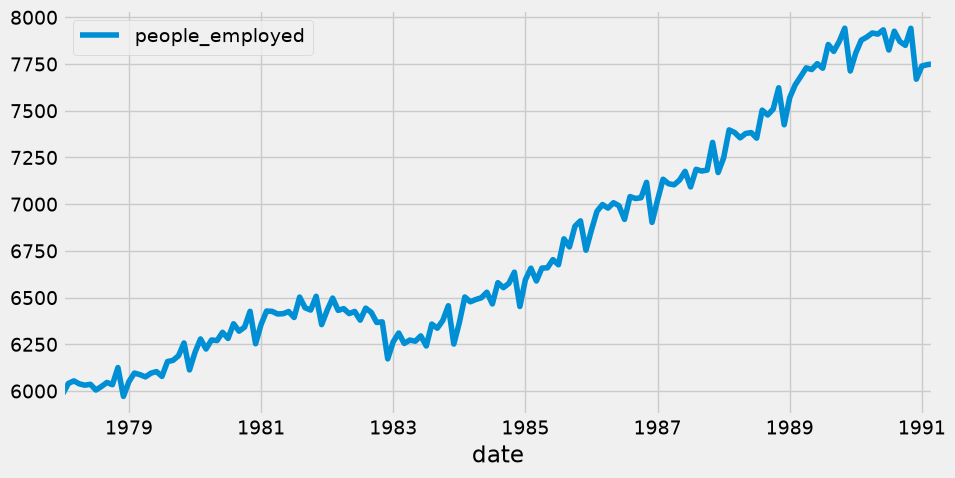

In [81]:
aus_employment.plot()
plt.show()

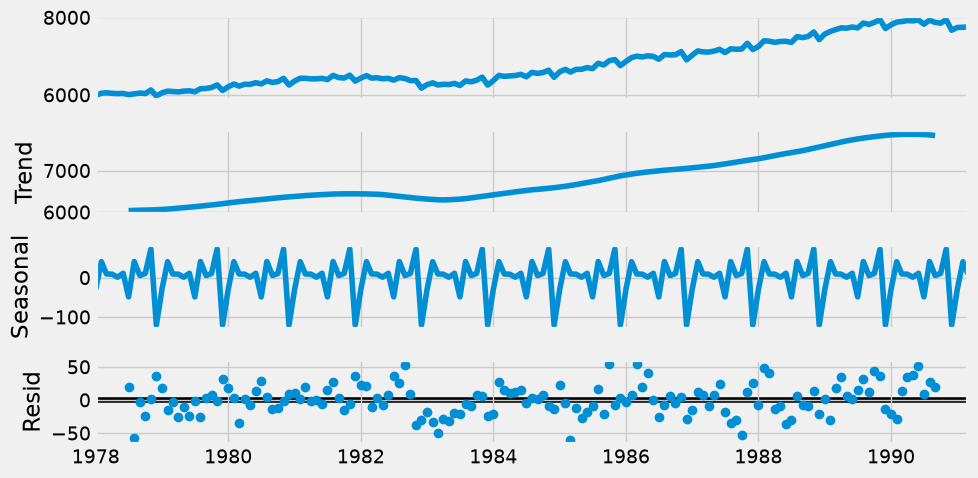

In [82]:

# Perform additive decomposition
decomp = seasonal_decompose(aus_employment, period=12)

# Plot decomposition
decomp.plot();
plt.tight_layout();

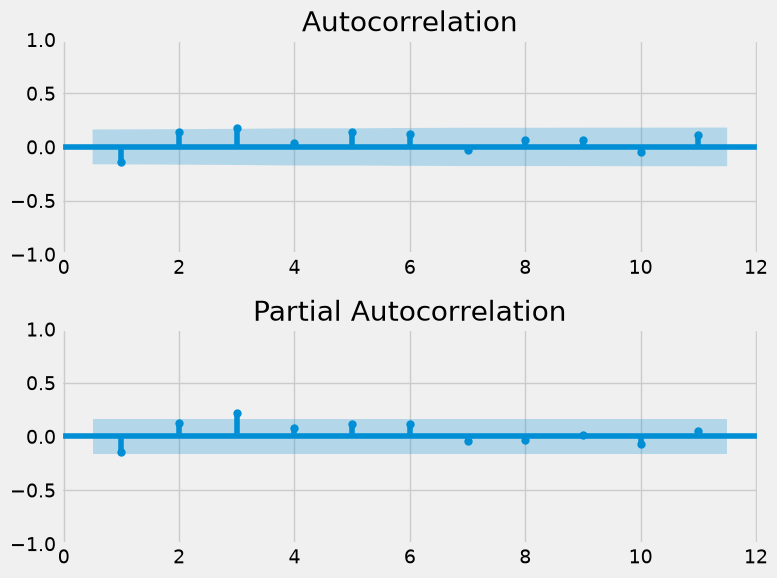

In [83]:
from statsmodels.graphics.tsaplots import plot_pacf

# Take the first and seasonal differences and drop NaNs
aus_employment_diff = aus_employment.diff().diff(12).dropna()

# Create the figure 
fig, (ax1, ax2) = plt.subplots(2,1,figsize=(8,6))

# Plot the ACF on ax1
plot_acf(aus_employment_diff, lags=11, zero=False, ax=ax1);

# Plot the PACF on ax2
plot_pacf(aus_employment_diff, lags=11, zero=False, ax=ax2);
plt.tight_layout();

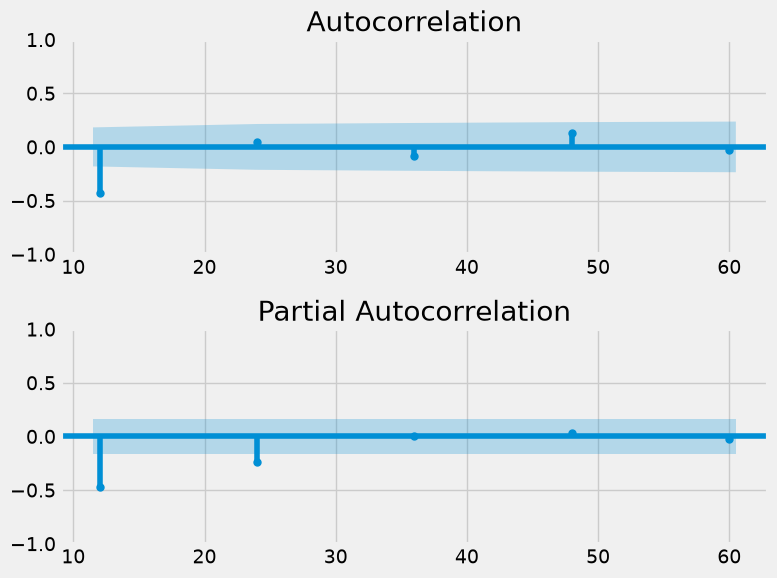

In [84]:
# Make list of lags
lags = [12, 24, 36, 48, 60]

# Create the figure 
fig, (ax1, ax2) = plt.subplots(2,1,figsize=(8,6))

# Plot the ACF on ax1
plot_acf(aus_employment_diff, lags=lags, zero=False, ax=ax1);

# Plot the PACF on ax2
plot_pacf(aus_employment_diff, lags=lags, zero=False, ax=ax2);
plt.tight_layout();

## Selección del Modelo SARIMA

La **ACF no estacional** no presenta un patrón claro de un modelo AR, MA o ARMA, por lo que no se incluyen componentes no estacionales:

$$
p=0,\qquad q=0
$$

La **ACF y PACF estacionales** muestran un comportamiento característico de un **MA estacional de orden 1**, por lo que:

$$
P=0,\qquad Q=1,\qquad S=12
$$

Por tanto, el modelo seleccionado es:

$$
\boxed{\text{SARIMAX}(0,1,0)(0,1,1)_{12}}
$$

---

# Pronósticos: SARIMA vs ARIMA

En este ejercicio se comparan dos modelos ajustados sobre la serie de empleo de Wisconsin:

- **ARIMA(3,1,2)**
- **SARIMA(0,1,1)(1,1,1)_{12}**

Ambos modelos fueron seleccionados por tener los menores valores de **AIC** dentro de sus respectivas familias.

El objetivo es:

- Generar pronósticos dinámicos para los siguientes **25 meses**.
- Comparar las predicciones con los datos reales (`wisconsin_test`).
- Evaluar el impacto de incorporar la **estacionalidad** en el modelo.

### Resultado esperado

✅ El modelo **SARIMA** debería producir mejores pronósticos, ya que la serie presenta una fuerte componente estacional anual (\(S=12\)), algo que el modelo **ARIMA** no puede capturar explícitamente.

En general:

> Para series con estacionalidad, los modelos **SARIMA** suelen superar a los modelos **ARIMA** tanto en ajuste como en capacidad predictiva.

In [85]:
wisconsin_test = pd.read_csv('./dataset/wisconsin_test.csv', index_col='date', parse_dates=True)
wisconsin_test = wisconsin_test.asfreq('MS')
dates = wisconsin_test.index
wisconsin_test.head()

,number_in_employment
date,
1973-10-01,374.5
1973-11-01,380.2
1973-12-01,384.6
1974-01-01,360.6
1974-02-01,354.4


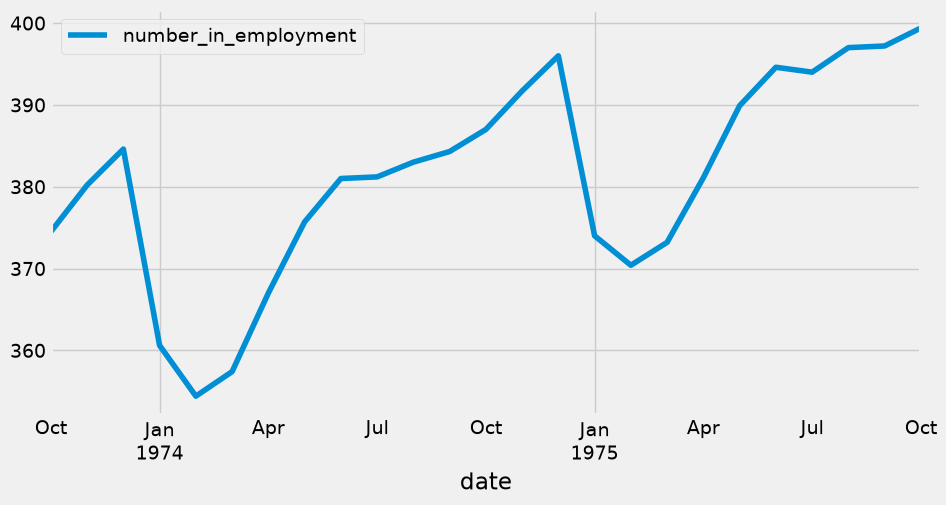

In [86]:
wisconsin_test.plot()
plt.show()

In [87]:
model = SARIMAX(wisconsin_test, order=(3, 1, 2), trend='c', 
                enforce_stationarity=True, enforce_invertibility=True)

arima_results = model.fit()

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [88]:
model = SARIMAX(wisconsin_test, order=(0, 1, 1), seasonal_order=(1, 1, 1, 12), trend='c', 
                enforce_stationarity=True, enforce_invertibility=True)

sarima_results = model.fit()

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [89]:
arima_results.specification

{'seasonal_periods': 0,
 'measurement_error': False,
 'time_varying_regression': False,
 'simple_differencing': False,
 'enforce_stationarity': True,
 'enforce_invertibility': True,
 'hamilton_representation': False,
 'concentrate_scale': False,
 'trend_offset': 1,
 'order': (3, 1, 2),
 'seasonal_order': (0, 0, 0, 0),
 'k_diff': 1,
 'k_seasonal_diff': 0,
 'k_ar': 3,
 'k_ma': 2,
 'k_seasonal_ar': 0,
 'k_seasonal_ma': 0,
 'k_ar_params': 3,
 'k_ma_params': 2,
 'trend': 'c',
 'k_trend': 1,
 'k_exog': 0,
 'mle_regression': False,
 'state_regression': False}

In [90]:
sarima_results.specification

{'seasonal_periods': 12,
 'measurement_error': False,
 'time_varying_regression': False,
 'simple_differencing': False,
 'enforce_stationarity': True,
 'enforce_invertibility': True,
 'hamilton_representation': False,
 'concentrate_scale': False,
 'trend_offset': 1,
 'order': (0, 1, 1),
 'seasonal_order': (1, 1, 1, 12),
 'k_diff': 1,
 'k_seasonal_diff': 1,
 'k_ar': 0,
 'k_ma': 1,
 'k_seasonal_ar': 12,
 'k_seasonal_ma': 12,
 'k_ar_params': 0,
 'k_ma_params': 1,
 'trend': 'c',
 'k_trend': 1,
 'k_exog': 0,
 'mle_regression': False,
 'state_regression': False}

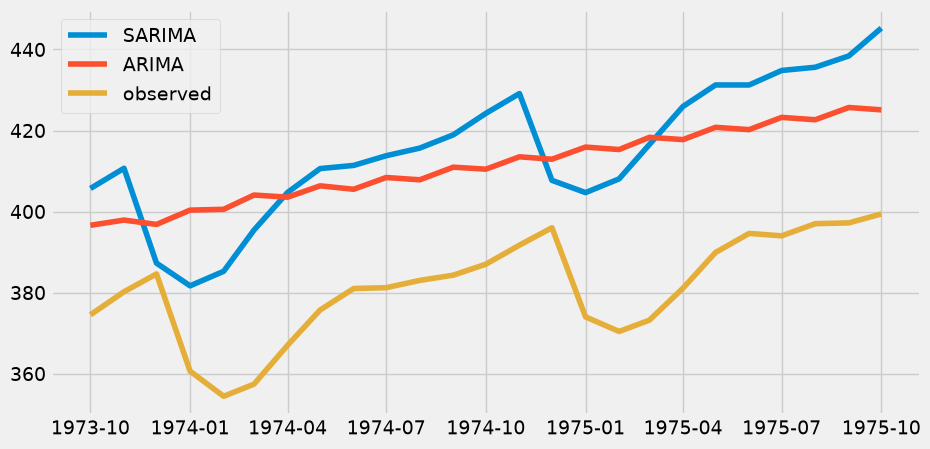

In [91]:
# Create ARIMA mean forecast
arima_pred = arima_results.get_forecast(25)
arima_mean = arima_pred.predicted_mean

# Create SARIMA mean forecast
sarima_pred = sarima_results.get_forecast(25)
sarima_mean = sarima_pred.predicted_mean

# Plot mean ARIMA and SARIMA predictions and observed
plt.plot(dates, sarima_mean, label='SARIMA');
plt.plot(dates, arima_mean, label='ARIMA');
plt.plot(wisconsin_test, label='observed');
plt.legend();

# Automatización y Ahorro de Tiempo

## Selección Automática de Modelos

El paquete `pmdarima` es una herramienta muy útil para **seleccionar automáticamente los órdenes de un modelo ARIMA o SARIMA**.

A partir de la información obtenida en la etapa de identificación (ACF, PACF y estacionalidad), se puede restringir la búsqueda de modelos y dejar que el algoritmo encuentre la mejor combinación de parámetros.

```python
import pmdarima as pm

modelo = pm.auto_arima(
    serie,
    seasonal=True,
    m=12
)

## Selección Automática con `pmdarima`

El paquete `pmdarima` permite **seleccionar automáticamente** los órdenes de un modelo ARIMA o SARIMA.

### Ventajas
- Ahorra tiempo.
- Evalúa múltiples modelos.
- Selecciona el mejor según AIC o BIC.

### Limitaciones
⚠️ Puede equivocarse si la serie tiene:

- Outliers.
- Datos faltantes.
- Cambios estructurales.

> `pmdarima` es una ayuda, pero no reemplaza el análisis del experto.

In [92]:
import pmdarima as pm

# Create auto_arima model
model1 = pm.auto_arima(df1,
                      seasonal=True, m=7,
                      d=0, D=1,
                      max_p=2, max_q=2,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True)

# Print model summary
print(model1.summary())

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[7] intercept   : AIC=inf, Time=0.29 sec
 ARIMA(0,0,0)(0,1,0)[7] intercept   : AIC=1124.433, Time=0.01 sec
 ARIMA(1,0,0)(1,1,0)[7] intercept   : AIC=1120.434, Time=0.07 sec
 ARIMA(0,0,1)(0,1,1)[7] intercept   : AIC=1122.218, Time=0.04 sec
 ARIMA(0,0,0)(0,1,0)[7]             : AIC=1122.596, Time=0.00 sec
 ARIMA(1,0,0)(0,1,0)[7] intercept   : AIC=1125.048, Time=0.01 sec
 ARIMA(1,0,0)(2,1,0)[7] intercept   : AIC=1119.909, Time=0.11 sec
 ARIMA(1,0,0)(2,1,1)[7] intercept   : AIC=1121.791, Time=0.11 sec
 ARIMA(1,0,0)(1,1,1)[7] intercept   : AIC=1120.954, Time=0.09 sec
 ARIMA(0,0,0)(2,1,0)[7] intercept   : AIC=1119.066, Time=0.08 sec
 ARIMA(0,0,0)(1,1,0)[7] intercept   : AIC=1119.294, Time=0.04 sec
 ARIMA(0,0,0)(2,1,1)[7] intercept   : AIC=1120.813, Time=0.10 sec
 ARIMA(0,0,0)(1,1,1)[7] intercept   : AIC=1120.054, Time=0.05 sec
 ARIMA(0,0,1)(2,1,0)[7] intercept   : AIC=1119.937, Time=0.07 sec
 ARIMA(1,0,1)(2,1,0)[7] intercept   : 

In [93]:
# Create model
model2 = pm.auto_arima(df2,
                       seasonal=False,
                       d=1,
                       trend='c',
                      max_p=2, max_q=2,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True)

# Print model summary
print(model2.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=1131.956, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1153.963, Time=0.00 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1155.355, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1155.747, Time=0.01 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1153.963, Time=0.00 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1136.103, Time=0.05 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=1130.992, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1149.020, Time=0.04 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=1132.526, Time=0.03 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=1130.992, Time=0.03 sec

Best model:  ARIMA(2,1,1)(0,0,0)[0] intercept
Total fit time: 0.253 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   80
Model:               SARIMAX(2, 1, 1)   Log Likelihood        

In [94]:
# Create model for SARIMAX(p,1,q)(P,1,Q)7
model3 = pm.auto_arima(df3,
                      seasonal=True, m=7,
                      d=1, D=1,
                      start_p=1, start_q=1,
                      max_p=1, max_q=1,
                      max_P=1, max_Q=1,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True)

# Print model summary
print(model3.summary())

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[7]             : AIC=inf, Time=0.14 sec
 ARIMA(0,1,0)(0,1,0)[7]             : AIC=1593.897, Time=0.00 sec
 ARIMA(1,1,0)(1,1,0)[7]             : AIC=1583.263, Time=0.04 sec
 ARIMA(0,1,1)(0,1,1)[7]             : AIC=inf, Time=0.07 sec
 ARIMA(1,1,0)(0,1,0)[7]             : AIC=1593.659, Time=0.01 sec
 ARIMA(1,1,0)(1,1,1)[7]             : AIC=inf, Time=0.08 sec
 ARIMA(1,1,0)(0,1,1)[7]             : AIC=inf, Time=0.06 sec
 ARIMA(0,1,0)(1,1,0)[7]             : AIC=1581.972, Time=0.01 sec
 ARIMA(0,1,0)(1,1,1)[7]             : AIC=inf, Time=0.05 sec
 ARIMA(0,1,0)(0,1,1)[7]             : AIC=1575.886, Time=0.03 sec
 ARIMA(1,1,1)(0,1,1)[7]             : AIC=inf, Time=0.12 sec
 ARIMA(0,1,0)(0,1,1)[7] intercept   : AIC=1577.811, Time=0.06 sec

Best model:  ARIMA(0,1,0)(0,1,1)[7]          
Total fit time: 0.679 seconds
                                      SARIMAX Results                                      
Dep. Variable:            

## Guardar y Actualizar Modelos

Una vez seleccionado un modelo mediante la metodología de **Box-Jenkins**, es importante:

- **Guardar** el modelo entrenado.
- **Actualizarlo** cuando se disponga de nuevas observaciones.

Esto es fundamental para llevar el modelo a **producción**.

```python
# Guardar el modelo
results.save('modelo.pkl')

# Cargar el modelo
from statsmodels.iolib.smpickle import load_pickle
modelo = load_pickle('modelo.pkl')

# Actualizar con nuevos datos
modelo = modelo.append(nuevos_datos)

In [95]:
import joblib

# Set model name
filename='candy_model.pkl'

# Pickle it
joblib.dump(model1, filename)

# Load the model back in
loaded_model = joblib.load(filename)

# Update the model
# loaded_model.update(df)

# SARIMA y la Metodología Box-Jenkins

## Box-Jenkins para Series Estacionales

1. Determinar si la serie presenta estacionalidad.
2. Identificar el período estacional \(S\).
3. Transformar la serie para hacerla estacionaria:
   - Diferenciación no estacional.
   - Diferenciación estacional.
   - Otras transformaciones (log, Box-Cox, etc.).

---

## Diagnóstico del Modelo SARIMA

La serie se ajusta mejor con el modelo:

$$
\boxed{\text{SARIMA}(1,1,1)(0,1,1)_{12}}
$$

con una constante incluida.

El objetivo es:

- Ajustar el modelo usando la clase `SARIMAX`.
- Verificar que los residuos se comporten como **ruido blanco**.
- Revisar:
  - Autocorrelación residual (Ljung-Box).
  - Normalidad (Jarque-Bera).
  - Homocedasticidad.
  - Gráficos de diagnóstico.

> Un buen modelo SARIMA debe dejar residuos sin estructura y aproximadamente aleatorios.

In [96]:
co2 = pd.read_csv('./dataset/co2.csv', index_col='date', parse_dates=True)
co2 = co2.asfreq('MS')
co2.head()

,CO2_ppm
date,
1958-03-01,315.71
1958-04-01,317.45
1958-05-01,317.50
1958-06-01,317.10
1958-07-01,315.86


In [ ]:
# Create model object
model = SARIMAX(co2, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12), trend='c',exog=)

# Fit model
results = model.fit()

In [98]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                            CO2_ppm   No. Observations:                  727
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -179.718
Date:                            Wed, 15 Jul 2026   AIC                            369.437
Time:                                    19:02:39   BIC                            392.291
Sample:                                03-01-1958   HQIC                           378.263
                                     - 09-01-2018                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0017      0.001      2.806      0.005       0.001       0.003
ar.L1          0.2412      0.078      3.073      0.002       0.087       0.395
ma.L1         -0.6079      0.065     -9.294      0.000      -0.736      -0.480
ma.S.L12      -0.8820      0.019    -45.504      0.000      -0.920      -0.844
sigma2         0.0944      0.005     20.751      0.000       0.085       0.103
===================================================================================
Ljung-Box (L1) (Q):                   0.08   Jarque-Bera (JB):                 6.19
Prob(Q):                              0.78   Prob(JB):                         0.05
Heteroskedasticity (H):               1.13   Skew:                             0.00
Prob(H) (two-sided):                  0.33   Kurtosis:                         3.46
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

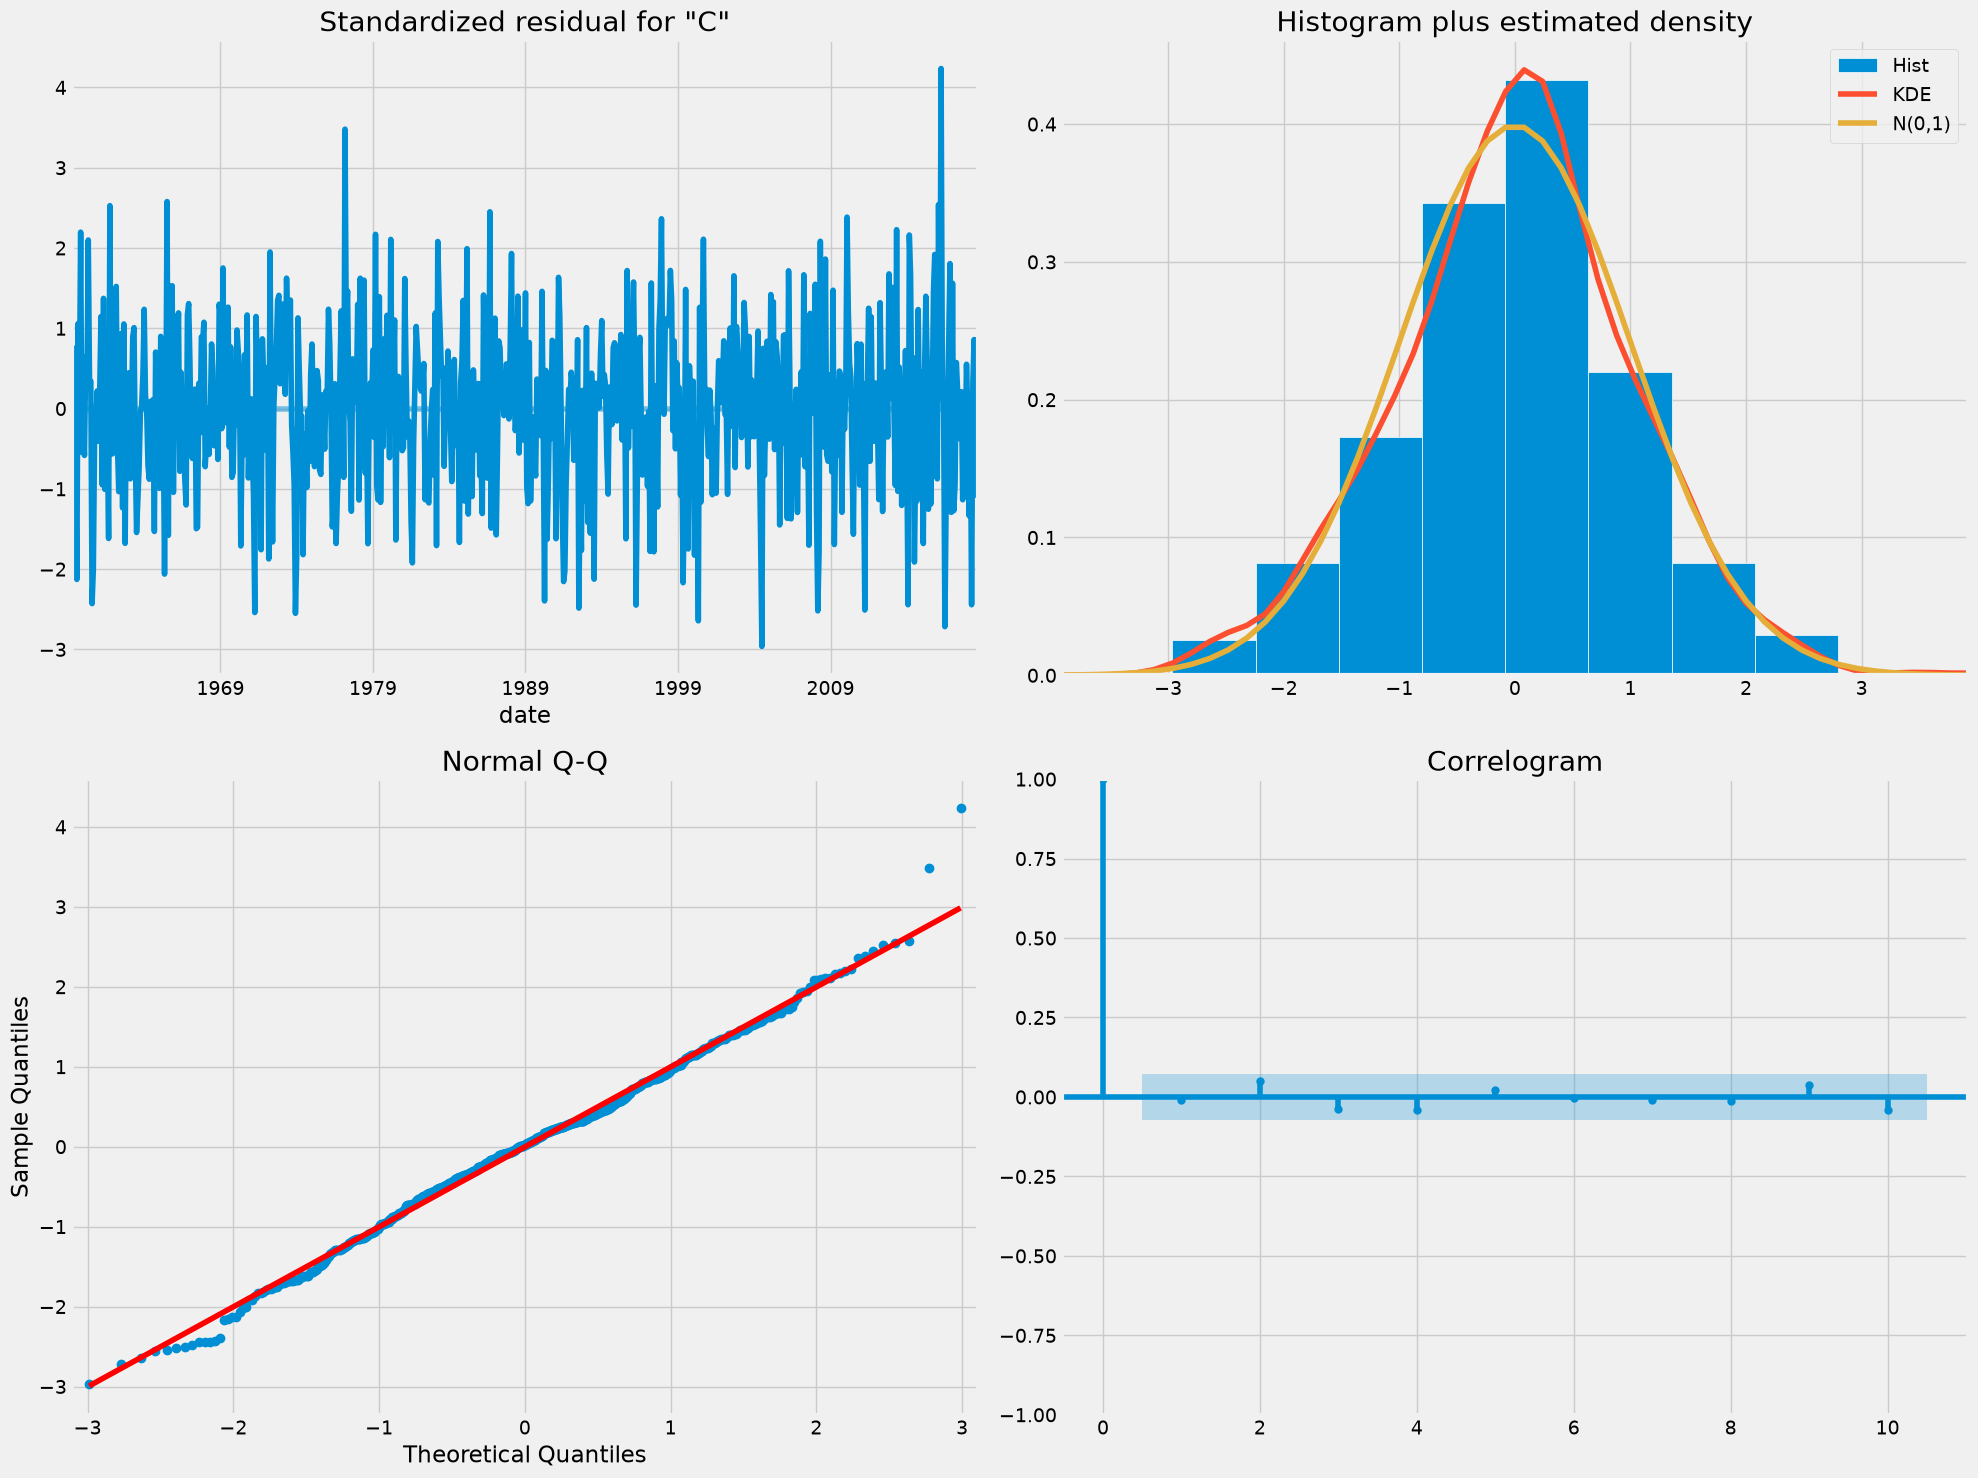

In [99]:
# Plot common diagnostics
results.plot_diagnostics(figsize=(20, 15));
plt.tight_layout();

# Pronóstico con un Modelo SARIMA

En el ejercicio anterior se verificó que el modelo:

$$
\boxed{\text{SARIMA}(1,1,1)(0,1,1)_{12}}
$$

proporciona un buen ajuste para la serie de **concentración de CO₂**.

Ahora el objetivo es utilizar este modelo para:

- Generar pronósticos futuros de la serie.
- Estimar los niveles de CO₂ hasta el año **2030**.
- Analizar qué ocurriría si las emisiones continúan siguiendo la tendencia histórica.

```python
forecast = results.get_forecast(steps=n_periodos)
pred = forecast.predicted_mean
ci = forecast.conf_int()

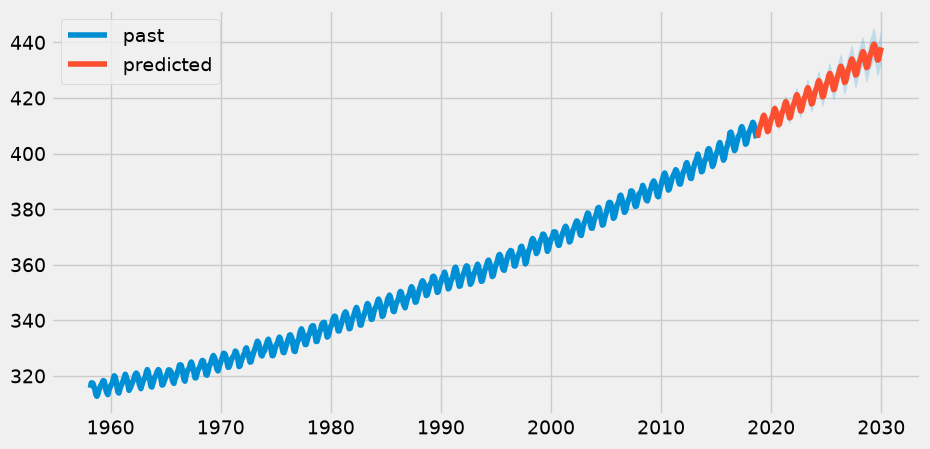

In [100]:
# Create forecast object
forecast_object = results.get_forecast(136)

# Extract predicted mean attribute
mean = forecast_object.predicted_mean

# Calculate the confidence intervals
conf_int = forecast_object.conf_int()

# Extract the forecast dates
dates = mean.index

plt.figure()

# Plot past CO2 levels
plt.plot(co2.index, co2, label='past');

# Plot the prediction means as line
plt.plot(dates, mean, label='predicted');

# Shade between the confidence intervals
plt.fill_between(dates, conf_int.loc[:, 'lower CO2_ppm'], 
                 conf_int.loc[:, 'upper CO2_ppm'], alpha=0.2);

# Plot legend
plt.legend();

In [101]:
# Print last predicted mean
print(mean.iloc[-1])

# Print last confidence interval
print(conf_int.iloc[-1])

438.1971866626412
lower CO2_ppm    432.113317
upper CO2_ppm    444.281056
Name: 2030-01-01 00:00:00, dtype: float64


# El Modelo SARIMAX

**S** – **Seasonal** (Estacional)  
**AR** – **AutoRegressive** (Autorregresivo)  
**I** – **Integrated** (Diferenciación)  
**MA** – **Moving Average** (Media Móvil)  
**X** – **Exogenous** (Variables Exógenas)

---

El modelo **SARIMAX** extiende el modelo SARIMA al incorporar variables externas que pueden ayudar a explicar o mejorar los pronósticos de la serie.

Su notación es:

$$
\text{SARIMAX}(p,d,q)(P,D,Q)_S + X
$$

donde **\(X\)** representa una o más variables explicativas externas.

### Ejemplos de variables exógenas

- Temperatura → pronóstico de demanda eléctrica.
- Promociones → pronóstico de ventas.
- Precio del petróleo → pronóstico de inflación.
- COVID-19 → modelar un shock estructural.

> **SARIMA** modela únicamente la información histórica de la serie, mientras que **SARIMAX** también incorpora información externa para mejorar la capacidad predictiva.